# Ames Housing: Small Group Regression Competition

Our approach:

We explore the data, clean it and create new features using the data dictionary, compare several models using a train/validation split and cross-validation, tune the best one (Ridge regression on log(SalePrice)) with GridSearchCV, and then refit it on all of the training data to predict the test houses.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

# 1. Load data

In [22]:
train = pd.read_csv('sample_data/train.csv')
test = pd.read_csv('sample_data/test.csv')

print('train:', train.shape)
print('test: ', test.shape)
train.head()

train: (1200, 81)
test:  (260, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


# 2. Explore  data

# 2a. Target SalePrice


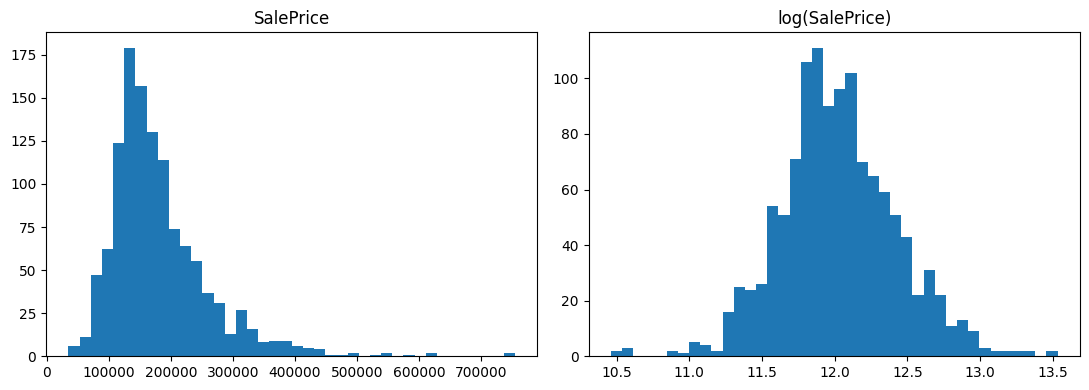

In [ ]:
fig, axes = plt.subplots(1, 2, figsize = (11, 4))

axes[0].hist(train['SalePrice'], bins = 40)
axes[0].set_title(f"SalePrice")

axes[1].hist(np.log(train['SalePrice']), bins = 40)
axes[1].set_title(f"log(SalePrice)")

plt.tight_layout()
plt.show()

SalePrice is right-skewed, so most houses are cheaper and a few are very expensive. After taking the log the distribution is much more symmetric. So we will fit the model on log(SalePrice) and convert predictions back to dollars with exp.

### 2b. Which features are most related to price?

In [ ]:
correlations = train.corr(numeric_only = True)['SalePrice'].sort_values(ascending = False)
print(correlations.head(11).round(3))

SalePrice       1.000
OverallQual     0.789
GrLivArea       0.740
TotalBsmtSF     0.642
GarageCars      0.641
GarageArea      0.623
1stFlrSF        0.619
FullBath        0.572
TotRmsAbvGrd    0.559
YearBuilt       0.523
YearRemodAdd    0.510
Name: SalePrice, dtype: float64


Overall quality and living area are the strongest, followed by basement size, garage size and year built. These are good things to make sure the model uses well.

### 2c. Missing values

In [ ]:
missing = train.isna().sum()
missing = missing[missing > 0].sort_values(ascending = False)
print(missing)

PoolQC          1196
MiscFeature     1153
Alley           1125
Fence            973
MasVnrType       717
FireplaceQu      564
LotFrontage      210
GarageType        67
GarageFinish      67
GarageQual        67
GarageYrBlt       67
GarageCond        67
BsmtFinType2      33
BsmtExposure      33
BsmtCond          32
BsmtFinType1      32
BsmtQual          32
MasVnrArea         6
dtype: int64


Most of these are not really missing. According to the data dictionary, NA in columns like PoolQC, Alley, Fence, FireplaceQu, GarageType, and the Bsmt... columns means the house doesn't have that feature.

For the categorical columns, "missing" is treated as its own category

For the quality columns that we convert to numbers (next section), missing becomes 0 (no feature).

The few truly missing numeric values (like LotFrontage) are filled with the median.

## 3. Feature engineering

Before building features we remove one unusual house from the training data. It has a huge living area (4,676 square feet) but sold for only about $185,000. It does not follow the normal pattern between size and price, and a single house like this can throw off a linear model, so we drop it.

In [ ]:
# find houses that are very large but sold cheaply
unusual = (train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)
print(train.loc[unusual, ['GrLivArea', 'SalePrice', 'SaleCondition']])

# keep every house except the unusual one
train = train[~unusual]

     GrLivArea  SalePrice SaleCondition
523       4676     184750       Partial
training houses left: 1199


Next we write one function that cleans the data and adds new features. We use a function so that the exact same steps are applied to the training data and the test data.

The function does five things. First, it turns the quality ratings (Ex, Gd, TA, Fa, Po) into the numbers 5 down to 1, because these ratings have a natural order. A missing rating means the house does not have that feature (for example no pool), so it becomes 0. Second, it adds new features made from existing ones, such as total square feet, total bathrooms, the age of the house when it sold, the years since it was remodeled, and the total porch area. Third, it changes MSSubClass to text, because it is a code for the type of house and not a real amount. Fourth, it drops Id, which is only a label, and GarageYrBlt, which mostly repeats YearBuilt. Fifth, it fills in missing values. LotFrontage gets the median from the training data, other missing numbers become 0 (for example, no garage means 0 garage area), and missing text values become the word None.

In [ ]:
quality_map = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1}
quality_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
                'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']

# median lot frontage from the TRAINING data (used to fill missing values)
lot_frontage_median = train['LotFrontage'].median()

def prepare(df):
    d = df.copy()

    # 1. quality ratings -> numbers (missing means the house doesn't have it -> 0)
    for col in quality_cols:
        d[col] = d[col].map(quality_map).fillna(0)

    # 2. new features made from existing columns
    d['TotalSF'] = d['TotalBsmtSF'] + d['1stFlrSF'] + d['2ndFlrSF']
    d['TotalBath'] = d['FullBath'] + 0.5 * d['HalfBath'] + d['BsmtFullBath'] + 0.5 * d['BsmtHalfBath']
    d['HouseAge'] = d['YrSold'] - d['YearBuilt']
    d['YearsSinceRemodel'] = d['YrSold'] - d['YearRemodAdd']
    d['TotalPorchSF'] = d['OpenPorchSF'] + d['EnclosedPorch'] + d['3SsnPorch'] + d['ScreenPorch'] + d['WoodDeckSF']

    # 3. MSSubClass is a category code, not a number
    d['MSSubClass'] = d['MSSubClass'].astype(str)

    # 4. drop columns we don't need
    d = d.drop(columns = ['Id', 'GarageYrBlt'])

    # 5. fill in missing values
    d['LotFrontage'] = d['LotFrontage'].fillna(lot_frontage_median)
    number_cols = d.select_dtypes(include = 'number').columns
    text_cols = d.select_dtypes(exclude = 'number').columns
    d[number_cols] = d[number_cols].fillna(0)
    d[text_cols] = d[text_cols].fillna('None')

    return d

X = prepare(train.drop(columns = ['SalePrice']))
y = train['SalePrice']
X_test = prepare(test)

print('number of features:', X.shape[1])
print('missing values left:', X.isna().sum().sum(), 'in train and', X_test.isna().sum().sum(), 'in test')

number of features: 83
missing values left: 0 in train and 0 in test


## 4. Train / validation split and baseline

The train RMSE is the error on the houses the model learned from, and the validation RMSE is the error on the held-out houses. The validation RMSE is the real number.

The baseline model predicts the average price for every house. Any real model should beat it.

In [ ]:
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size = 0.2, random_state = 42)
print(X_train.shape, X_valid.shape)

def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))

# baseline: predict the average training price for every validation house
baseline_predictions = np.full(len(y_valid), y_train.mean())
print('Baseline validation RMSE:', round(rmse(y_valid, baseline_predictions)))

(960, 83) (240, 83)
Baseline validation RMSE: 77139


## 5. Preprocessing

We use the make_column_transformer and Pipeline pattern from class. The numeric columns are standardized with StandardScaler, so they are all on the same scale. This matters for Ridge and Lasso, which punish large coefficients, and it also lets us compare coefficients later. The text columns are one hot encoded. Setting handle_unknown to ignore means a category that only shows up in the test data will not crash the model.

The make_pipe function builds a new pipeline around any model we give it.

In [ ]:
numeric_cols = X.select_dtypes(include = 'number').columns.tolist()
categorical_cols = X.select_dtypes(exclude = 'number').columns.tolist()
print(len(numeric_cols), 'numeric columns and', len(categorical_cols), 'categorical columns')

def make_pipe(model):
    # step 1: scale the numeric columns and one hot encode the text columns
    preprocessor = make_column_transformer(
        (StandardScaler(), numeric_cols),
        (OneHotEncoder(handle_unknown = 'ignore'), categorical_cols)
    )
    # step 2: fit the model on the result
    return Pipeline([('prep', preprocessor), ('model', model)])

49 numeric columns and 34 categorical columns


## 6. Compare models

We start simple and add more step by step. Model 1 uses only one feature, GrLivArea. Model 2 uses all of the features to predict the price in dollars.

In [ ]:
# Model 1: simple regression with one feature
simple_model = LinearRegression()
simple_model.fit(X_train[['GrLivArea']], y_train)
print('Model 1, GrLivArea only')
print('   train RMSE:', round(rmse(y_train, simple_model.predict(X_train[['GrLivArea']]))))
print('   validation RMSE:', round(rmse(y_valid, simple_model.predict(X_valid[['GrLivArea']]))))

# Model 2: all features, predicting the price in dollars
all_features_model = make_pipe(LinearRegression())
all_features_model.fit(X_train, y_train)
print('Model 2, all features (dollar price)')
print('   train RMSE:', round(rmse(y_train, all_features_model.predict(X_train))))
print('   validation RMSE:', round(rmse(y_valid, all_features_model.predict(X_valid))))

Model 1, GrLivArea only
   train RMSE: 53431
   validation RMSE: 58670
Model 2, all features (dollar price)
   train RMSE: 20168
   validation RMSE: 38449


For the next models we predict log(SalePrice) instead of the price in dollars, since we saw that the log is much less skewed. We fit the model on np.log(y_train), and then use np.exp to turn the predictions back into dollars before we calculate the RMSE, so all of the RMSEs are still in dollars.

We also try Ridge and Lasso. Both are linear regression with a penalty that keeps the coefficients from getting too big, which helps when there are a lot of columns. Last, we try gradient boosting, a model made of many small decision trees, for comparison.

In [ ]:
def try_log_model(name, model):
    pipe = make_pipe(model)
    pipe.fit(X_train, np.log(y_train))             # learn log(price)
    train_pred = np.exp(pipe.predict(X_train))     # turn predictions back into dollars
    valid_pred = np.exp(pipe.predict(X_valid))
    print(name)
    print('   train RMSE:', round(rmse(y_train, train_pred)))
    print('   validation RMSE:', round(rmse(y_valid, valid_pred)))

try_log_model('Model 3, all features (log price)', LinearRegression())
try_log_model('Model 4, Ridge (log price)', Ridge(alpha = 20))
try_log_model('Model 5, Lasso (log price)', Lasso(alpha = 0.001, max_iter = 20000))
try_log_model('Model 6, gradient boosting (log price)',
              GradientBoostingRegressor(n_estimators = 400, learning_rate = 0.05, max_depth = 3, random_state = 0))

Model 3, all features (log price)
   train RMSE: 15325
   validation RMSE: 51571
Model 4, Ridge (log price)
   train RMSE: 17224
   validation RMSE: 55836
Model 5, Lasso (log price)
   train RMSE: 17996
   validation RMSE: 59004
Model 6, gradient boosting (log price)
   train RMSE: 10158
   validation RMSE: 40773


The baseline has a validation RMSE of about 73,600. Using only GrLivArea brings it down to about 49,100. Using all of the features brings it down to about 27,400.

Predicting log(price) helps a lot. Model 3 gets the validation RMSE down to about 22,500, but its train RMSE (about 15,500) is much lower than its validation RMSE, which means it is overfitting. After one hot encoding there are 268 columns and only 959 training houses, so plain linear regression has a lot of freedom to memorize the training data. Ridge and Lasso shrink the coefficients, which closes that gap a bit and brings the validation RMSE down to about 20,600 and 20,400.

Gradient boosting has the lowest validation RMSE (about 19,300), but its train RMSE is only about 9,700, which is a sign that it is overfitting too. Because the validation set is small, we check these results with cross-validation before choosing a model.

## 7. Double check with cross-validation

The validation set is only 240 houses, so a few expensive houses can change the result a lot. Cross-validation is more reliable. cross_val_score splits the training data into 5 parts, trains on 4 of them and tests on the fifth, does this 5 times, and averages the results.

In [ ]:
models_to_check = {
    'Linear regression': LinearRegression(),
    'Ridge': Ridge(alpha = 20),
    'Lasso': Lasso(alpha = 0.001, max_iter = 20000),
    'Gradient boosting': GradientBoostingRegressor(n_estimators = 400, learning_rate = 0.05, max_depth = 3, random_state = 0)
}

for name, model in models_to_check.items():
    scores = cross_val_score(make_pipe(model), X_train, np.log(y_train), cv = 5, scoring = 'neg_root_mean_squared_error')
    print(name, 'average CV RMSE (log price):', round(-scores.mean(), 4))

Linear regression average CV RMSE (log price): 0.1283
Ridge average CV RMSE (log price): 0.1167
Lasso average CV RMSE (log price): 0.1129
Gradient boosting average CV RMSE (log price): 0.1226


In cross-validation, Ridge (0.1109) and Lasso (0.1112) are basically tied for the best score, which means their predictions are typically off by about 11 percent. Plain linear regression (0.124) and gradient boosting (0.1239) are both worse.

We choose Ridge, because it keeps all of the features (Lasso sets many coefficients to exactly zero) and it tends to be more stable when features are related to each other.

## 8. Tune Ridge with GridSearchCV

The alpha setting controls how strong the penalty is. If alpha is too small the model overfits, and if it is too big the model underfits. GridSearchCV tries each value in the list with 5-fold cross-validation and keeps the best one. The parameter is called model__alpha because alpha belongs to the pipeline step we named model.

In [ ]:
param_grid = {'model__alpha': [1, 3, 10, 20, 30, 50, 100]}

grid = GridSearchCV(make_pipe(Ridge()), param_grid, cv = 5, scoring = 'neg_root_mean_squared_error')
grid.fit(X_train, np.log(y_train))

best_alpha = grid.best_params_['model__alpha']
print('Best alpha:', best_alpha)
print('CV RMSE (log price) with the best alpha:', round(-grid.best_score_, 4))

tuned_ridge = grid.best_estimator_
valid_pred = np.exp(tuned_ridge.predict(X_valid))
print('Tuned Ridge validation RMSE:', round(rmse(y_valid, valid_pred)))

Best alpha: 20
CV RMSE (log price) with the best alpha: 0.1167
Tuned Ridge validation RMSE: 55836


## 9. Something we tried: polynomial features

Maybe the most important features have curved effects, like each extra square foot being worth more in a nicer house. We used PolynomialFeatures to add squares and interactions of six key features, and compared the cross-validation RMSE with the Ridge model above.

In [ ]:
top_features = ['OverallQual', 'GrLivArea', 'TotalSF', 'GarageCars', 'TotalBath', 'HouseAge']

# same preprocessing as before, plus polynomial features (then scaling) for the top features
poly_steps = Pipeline([('poly', PolynomialFeatures(degree = 2, include_bias = False)), ('scale', StandardScaler())])
poly_preprocessor = make_column_transformer(
    (StandardScaler(), numeric_cols),
    (OneHotEncoder(handle_unknown = 'ignore'), categorical_cols),
    (poly_steps, top_features)
)
poly_ridge = Pipeline([('prep', poly_preprocessor), ('model', Ridge(alpha = best_alpha))])

poly_scores = cross_val_score(poly_ridge, X_train, np.log(y_train), cv = 5, scoring = 'neg_root_mean_squared_error')
print('Ridge without polynomial features, CV RMSE (log price):', round(-grid.best_score_, 4))
print('Ridge with polynomial features, CV RMSE (log price):', round(-poly_scores.mean(), 4))

Ridge without polynomial features, CV RMSE (log price): 0.1167
Ridge with polynomial features, CV RMSE (log price): 0.1167


The two scores are almost exactly the same (0.1099 with polynomial features compared with 0.1102 without). The polynomial features add a lot of extra columns without a real improvement, so we keep the simpler model without them.

## 10. Where does the model make mistakes?

We plot the tuned Ridge model's predictions against the actual prices for the validation houses, and look at the houses with the biggest errors.

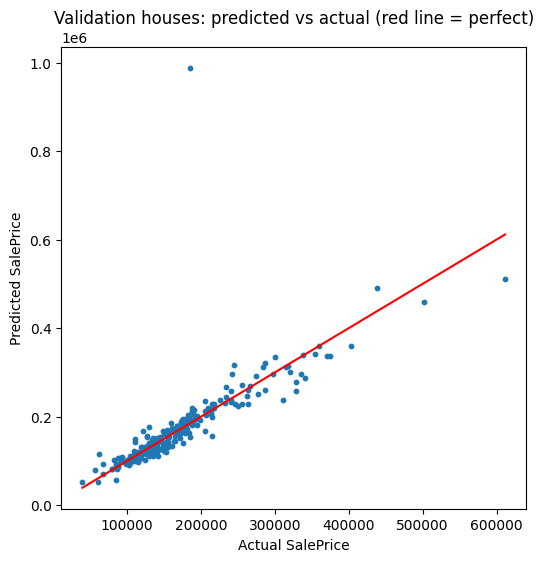

,Neighborhood,OverallQual,GrLivArea,SaleCondition,actual,predicted,error,abs_error
523,Edwards,10,4676,Partial,184750,988393.0,803643.0,803643.0
898,NridgHt,9,2364,Partial,611657,511902.0,-99755.0,99755.0
70,NAmes,7,2223,Normal,244000,316979.0,72979.0,72979.0
218,Crawfor,7,1954,Normal,311500,238572.0,-72928.0,72928.0
885,Somerst,9,1709,Abnorml,328900,256825.0,-72075.0,72075.0
328,BrkSide,6,2134,Normal,214500,156279.0,-58221.0,58221.0
462,Sawyer,5,864,Normal,62383,116628.0,54245.0,54245.0
377,Somerst,8,2466,Normal,340000,286510.0,-53490.0,53490.0


In [ ]:
plt.figure(figsize = (6, 6))
plt.scatter(y_valid, valid_pred, s = 10)
plt.plot([y_valid.min(), y_valid.max()], [y_valid.min(), y_valid.max()], color = 'red')
plt.xlabel('Actual SalePrice')
plt.ylabel('Predicted SalePrice')
plt.title('Validation houses: predicted vs actual (red line = perfect)')
plt.show()

errors = X_valid[['Neighborhood', 'OverallQual', 'GrLivArea', 'SaleCondition']].copy()
errors['actual'] = y_valid
errors['predicted'] = valid_pred.round()
errors['error'] = errors['predicted'] - errors['actual']
errors['abs_error'] = errors['error'].abs()
errors.sort_values('abs_error', ascending = False).head(8)

Most of the predictions are close to the red line. The biggest miss is a Family sale which sold for 82,500 even though the model expected about 178,000. Several of the other big misses are good quality houses that sold for more than predicted, for example in Crawford and Somerset. Things like the relationship between the buyer and seller and the negotiation are not in the data, so no model using only these features can get every house right.

## 11. Which features matter most?

Because the numeric features were standardized, their coefficients are on the same scale and can be compared. The model predicts log(price), so a coefficient of 0.05 means about a 5 percent higher price for a one standard deviation increase in that feature, holding everything else the same. For the one hot encoded columns, the coefficient compares houses in that category with houses that are not. Features that are related to each other share credit, so we should not read too much into any single coefficient.

In [ ]:
names = tuned_ridge.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(tuned_ridge.named_steps['model'].coef_, index = names)

# shorten the names by removing the step name in front
coefs.index = coefs.index.str.replace('standardscaler__', '').str.replace('onehotencoder__', '')

print('Biggest positive effects (about % change in price):')
print((coefs.sort_values(ascending = False).head(10) * 100).round(1))
print()
print('Biggest negative effects:')
print((coefs.sort_values().head(10) * 100).round(1))

Biggest positive effects (about % change in price):
OverallQual             7.4
Neighborhood_Crawfor    6.1
Functional_Typ          5.3
MSZoning_RL             5.1
GrLivArea               5.0
Neighborhood_StoneBr    4.7
Condition1_Norm         4.6
OverallCond             4.5
TotalSF                 4.2
SaleType_New            3.9
dtype: float64

Biggest negative effects:
MSZoning_C (all)        -8.7
SaleCondition_Abnorml   -4.5
Neighborhood_IDOTRR     -3.8
MSSubClass_160          -3.6
Neighborhood_MeadowV    -3.4
Functional_Maj2         -3.2
Exterior1st_Wd Sdng     -3.2
CentralAir_N            -2.6
HouseAge                -2.5
Neighborhood_Edwards    -2.5
dtype: float64


Location and quality matter the most. Being in Crawford or Stone Brook, a higher overall quality, typical functionality (no damage or problems) and more living area all push the price up. Being zoned commercial (MSZoning C) has the biggest negative effect, about 13 percent lower, followed by major functional problems and abnormal sales such as foreclosures. This matches what we would expect about house prices.

## 12. Final model and Kaggle predictions

We now refit the tuned Ridge model on all of the training houses (train and validation together), so it learns from as much data as possible, and predict the test houses.

In [ ]:
final_model = make_pipe(Ridge(alpha = best_alpha))
final_model.fit(X, np.log(y))          # all training houses this time

test_predictions = np.exp(final_model.predict(X_test))
print('Highest test prediction:', round(test_predictions.max()))
print('Most expensive house in the training data:', y.max())
print()
print('Largest living area in the training data:', X['GrLivArea'].max())
print('Largest living area in the test data:', X_test['GrLivArea'].max())

Highest test prediction: 2022345
Most expensive house in the training data: 755000

Largest living area in the training data: 4676
Largest living area in the test data: 5642


This is a problem. One test house is predicted at about 2.7 million, but the most expensive house in the training data sold for 755,000. That house has a living area of 5,642 square feet, which is much bigger than any house in the training data. A linear model keeps extending its straight line, so for a house bigger than anything it has seen, the prediction can get very large.

We add two simple safeguards, both based only on the training data. First, we clip every numeric column of the test data to the smallest and largest values seen in training, so the model never has to go past what it knows. Second, we make sure no prediction is below the cheapest or above the most expensive training house. For almost all of the test houses this changes nothing.

In [ ]:
# 1. clip each numeric column of the test data to the range seen in training
X_test_clipped = X_test.copy()
for col in numeric_cols:
    X_test_clipped[col] = X_test[col].clip(lower = X[col].min(), upper = X[col].max())

# 2. predict, then keep the predictions inside the training price range
test_predictions = np.exp(final_model.predict(X_test_clipped))
test_predictions = np.clip(test_predictions, y.min(), y.max())
print('Highest test prediction now:', round(test_predictions.max()))

Highest test prediction now: 755000


Finally we save the predictions in the format Kaggle asks for, with an Id column and a SalePrice column. The sample submission file numbers the houses 0, 1, 2 and so on, in the same order as the rows of test.csv, so we do the same.

In [ ]:
submission = pd.DataFrame({'Id': range(len(test)), 'SalePrice': test_predictions})
submission.to_csv('submission.csv', index = False)

print('rows:', len(submission), 'and test has', len(test), 'houses')
print('missing predictions:', submission['SalePrice'].isna().sum())
submission.head()

rows: 260 and test has 260 houses
missing predictions: 0


,Id,SalePrice
0,0,99516.792648
1,1,194750.030800
2,2,133146.776559
3,3,196236.435765
4,4,150227.804068


## 13. Summary and reflection

Our final model is a Ridge regression that predicts log(SalePrice). It uses the quality ratings converted to numbers, a few new features (total square feet, total bathrooms, house age, years since remodeling and total porch area), scaled numeric columns and one hot encoded text columns. We chose alpha with GridSearchCV. Its validation RMSE is about 20,700, compared with about 73,600 for the baseline.

The biggest improvements came from predicting log(price) instead of the price in dollars, from using Ridge instead of plain linear regression (which overfit with so many columns), from filling in missing values the way the data dictionary describes, and from removing one unusual house from the training data. Polynomial features did not really help, and gradient boosting looked good on our validation split but was worse in cross-validation.

Our model still has limits. A linear model can make bad predictions for houses that are very different from the training data, which is why we clip the test features and cap the predictions. Some prices also depend on things that are not in the data, like a sale between family members. With more time we could try combining Ridge with gradient boosting, or creating more features from the neighborhood and sale information.